In [1]:
# Quantitative Analysis of Risk and Return for a Multi-Asset Financial Portfolio Using Python

In [2]:
# Import all the packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import yfinance as yf

In [3]:
# JPM: JP Morgan
# MS: Morgan Stanley
# BAC: Bank of America

In [4]:
# Download Stock Data from Yahoo Finance

tickers = ['JPM', 'MS', 'BAC']
start_date = '2025-01-01'
end_date = '2026-01-06'
data = yf.download(tickers, start = start_date, end = end_date)['Close']
data

[*********************100%***********************]  3 of 3 completed


Ticker,BAC,JPM,MS
Date,,,
2025-01-02,42.604237,230.583771,119.413132
2025-01-03,43.104443,233.735092,120.523232
2025-01-06,43.671989,232.595535,123.107094
2025-01-07,44.326107,234.836014,121.422806
2025-01-08,44.451153,234.797409,122.360649
...,...,...,...
2025-12-29,54.476421,317.632477,177.022461
2025-12-30,54.407528,317.308746,176.176407
2025-12-31,54.131947,316.131409,174.651535


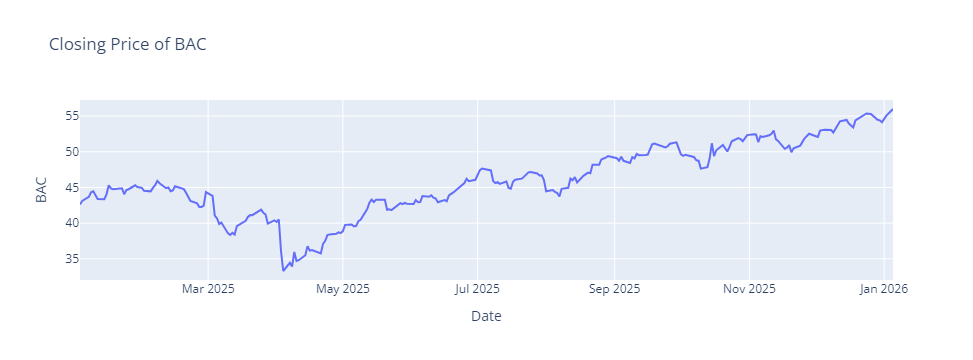

In [5]:
# Visualize Stocks Data
px.line(data, x = data.index, y = data['BAC'], title = 'Closing Price of BAC')

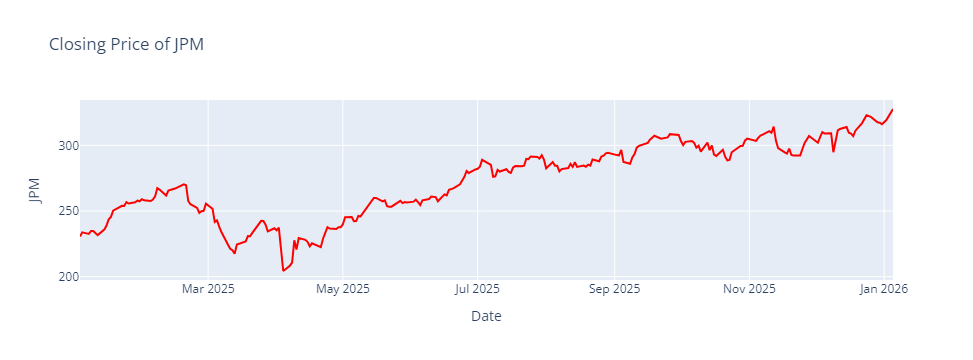

In [6]:
# Visualize Stocks Data
px.line(data, x = data.index, y = data['JPM'], title = 'Closing Price of JPM', color_discrete_sequence= ['red'])

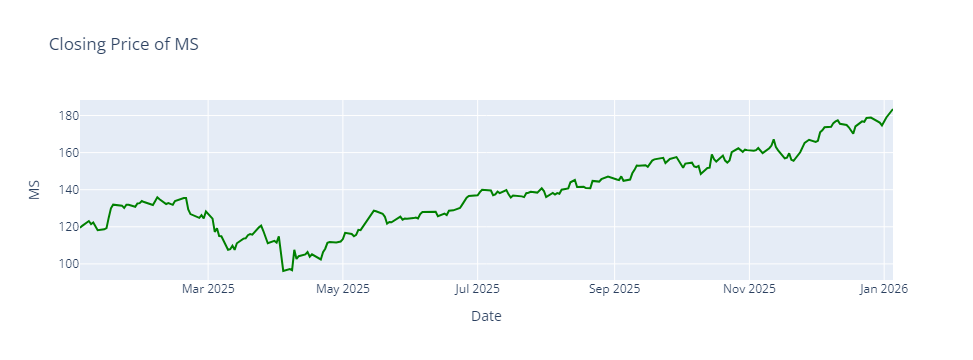

In [7]:
# Visualize Stocks Data
px.line(data, x = data.index, y = data['MS'], title = 'Closing Price of MS', color_discrete_sequence = ['green'])

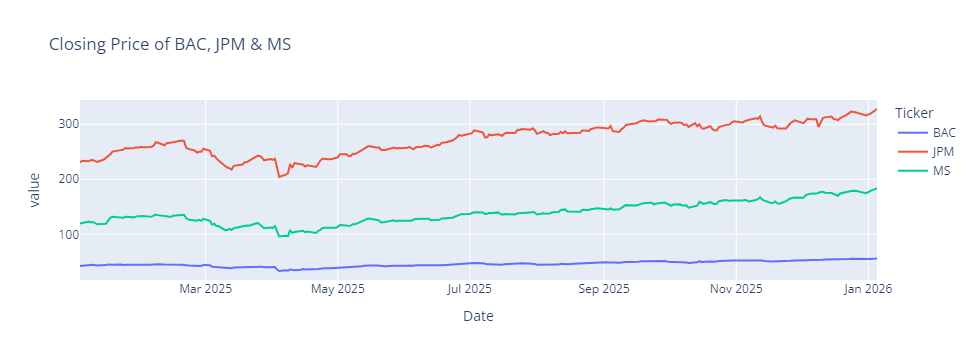

In [8]:
# Visualize All Stocks Data
px.line(data, title = 'Closing Price of BAC, JPM & MS').show()

In [9]:
data.head()

Ticker,BAC,JPM,MS
Date,,,
2025-01-02,42.604237,230.583771,119.413132
2025-01-03,43.104443,233.735092,120.523232
2025-01-06,43.671989,232.595535,123.107094
2025-01-07,44.326107,234.836014,121.422806
2025-01-08,44.451153,234.797409,122.360649


In [10]:
# Calculate Simple Return => (St - St-1)/(St-1) or (St/St-1) - 1

simple_returns = data.pct_change()
simple_returns = simple_returns.dropna() # Drop nan values
simple_returns

Ticker,BAC,JPM,MS
Date,,,
2025-01-03,0.011741,0.013667,0.009296
2025-01-06,0.013167,-0.004875,0.021439
2025-01-07,0.014978,0.009633,-0.013681
2025-01-08,0.002821,-0.000164,0.007724
2025-01-10,-0.023804,-0.013409,-0.034491
...,...,...,...
2025-12-29,-0.014599,-0.012686,-0.010612
2025-12-30,-0.001265,-0.001019,-0.004779
2025-12-31,-0.005065,-0.003710,-0.008655


In [11]:
data

Ticker,BAC,JPM,MS
Date,,,
2025-01-02,42.604237,230.583771,119.413132
2025-01-03,43.104443,233.735092,120.523232
2025-01-06,43.671989,232.595535,123.107094
2025-01-07,44.326107,234.836014,121.422806
2025-01-08,44.451153,234.797409,122.360649
...,...,...,...
2025-12-29,54.476421,317.632477,177.022461
2025-12-30,54.407528,317.308746,176.176407
2025-12-31,54.131947,316.131409,174.651535


In [12]:
data.shift(1)

Ticker,BAC,JPM,MS
Date,,,
2025-01-02,NaN,NaN,NaN
2025-01-03,42.604237,230.583771,119.413132
2025-01-06,43.104443,233.735092,120.523232
2025-01-07,43.671989,232.595535,123.107094
2025-01-08,44.326107,234.836014,121.422806
...,...,...,...
2025-12-29,55.283482,321.713898,178.921173
2025-12-30,54.476421,317.632477,177.022461
2025-12-31,54.407528,317.308746,176.176407


In [13]:
# Calculate Log Return => ln (St/St-1)

log_returns = np.log(data/data.shift(1))
log_returns = log_returns.dropna() 
log_returns

Ticker,BAC,JPM,MS
Date,,,
2025-01-03,0.011672,0.013574,0.009253
2025-01-06,0.013081,-0.004887,0.021212
2025-01-07,0.014867,0.009586,-0.013776
2025-01-08,0.002817,-0.000164,0.007694
2025-01-10,-0.024092,-0.013499,-0.035100
...,...,...,...
2025-12-29,-0.014706,-0.012768,-0.010669
2025-12-30,-0.001265,-0.001020,-0.004791
2025-12-31,-0.005078,-0.003717,-0.008693


In [14]:
# Portfolio Simple Returns (Rp = w1r1 + w2r2 + w3r3) => [w1 w2 w3].[r1 r2 r3]

weights = np.array([1/3, 1/3, 1/3])
portfolio_simple_returns = simple_returns.dot(weights)
portfolio_simple_returns

Date
2025-01-03    0.011568
2025-01-06    0.009910
2025-01-07    0.003643
2025-01-08    0.003460
2025-01-10   -0.023901
                ...   
2025-12-29   -0.012632
2025-12-30   -0.002354
2025-12-31   -0.005810
2026-01-02    0.017335
2026-01-05    0.022870
Length: 251, dtype: float64

In [15]:
# Portfolio Log Returns (Rp = w1r1 + w2r2 + w3r3) => [w1 w2 w3].[r1 r2 r3]
weights = np.array([1/3, 1/3, 1/3])
portfolio_log_returns = log_returns.dot(weights)
portfolio_log_returns

Date
2025-01-03    0.011500
2025-01-06    0.009802
2025-01-07    0.003559
2025-01-08    0.003449
2025-01-10   -0.024230
                ...   
2025-12-29   -0.012714
2025-12-30   -0.002359
2025-12-31   -0.005829
2026-01-02    0.017170
2026-01-05    0.022603
Length: 251, dtype: float64

In [37]:
# Annualize Simple Return of our Portfolio - Simple Return => (1 + Avg(Returns))^252 - 1
annualized_simple_return = ((1 + portfolio_simple_returns.mean()) ** 252) - 1
print(annualized_simple_return)

0.47852878749472927


In [39]:
# Annualize Log Return of Portfolio - Log Return => Avg Returns * 252
annualized_log_return = portfolio_log_returns.mean() * 252
print(annualized_log_return)

0.35291270200667163


In [40]:
# Volatility
daily_volatility = np.std(portfolio_simple_returns)
annual_volatility = daily_volatility * np.sqrt(252)
print(annual_volatility)

0.2562679052312801


In [19]:
# Download SPY Data (Benchmark)
start_date = '2024-01-01'
end_date = '2025-01-01'
benchmark = yf.download('^GSPC', start = start_date, end = end_date)['Close']
benchmark = benchmark.pct_change() # Simple Returns for my S&P 500
benchmark = benchmark.dropna()
benchmark

[*********************100%***********************]  1 of 1 completed


Ticker,^GSPC
Date,
2024-01-03,-0.008016
2024-01-04,-0.003428
2024-01-05,0.001826
2024-01-08,0.014115
2024-01-09,-0.001478
...,...
2024-12-24,0.011043
2024-12-26,-0.000406
2024-12-27,-0.011056


In [20]:
portfolio_simple_returns.head()

Date
2025-01-03    0.011568
2025-01-06    0.009910
2025-01-07    0.003643
2025-01-08    0.003460
2025-01-10   -0.023901
dtype: float64

In [21]:
benchmark.head()

Ticker,^GSPC
Date,
2024-01-03,-0.008016
2024-01-04,-0.003428
2024-01-05,0.001826
2024-01-08,0.014115
2024-01-09,-0.001478


In [41]:
# Calculate Beta
# Beta = Covariance(Rp, Rm)/Var(Rm) 

portfolio_returns = portfolio_simple_returns.to_numpy().flatten()
benchmark_return = benchmark.to_numpy().flatten()
cov_matrix = np.cov(portfolio_returns, benchmark_return)
beta = cov_matrix[0,1]/cov_matrix[1,1]
print(beta)

0.03563713222300414


In [43]:
# Calculate Alpha => CAPM Formula to calculate Alpha

risk_free_rate = 0.07
alpha = (np.mean(portfolio_simple_returns) - risk_free_rate/252) - beta * (np.mean(benchmark) - risk_free_rate/252)
alpha = alpha * 252
print(alpha)

0.31585779649180135


In [48]:
portfolio_simple_returns

Date
2025-01-03    0.011568
2025-01-06    0.009910
2025-01-07    0.003643
2025-01-08    0.003460
2025-01-10   -0.023901
                ...   
2025-12-29   -0.012632
2025-12-30   -0.002354
2025-12-31   -0.005810
2026-01-02    0.017335
2026-01-05    0.022870
Length: 251, dtype: float64

In [49]:
# Sortino Ratio
negative_returns = portfolio_simple_returns[portfolio_simple_returns < 0]
downside_deviation = np.std(negative_returns) # Daily Downside Std Dev
downside_deviation = downside_deviation * np.sqrt(252) # Annualized Downside Std Dev
print(downside_deviation)

0.22850873851105313


In [50]:
# Sharpe Ratio = (Rp - Rf)/sigma => Total Volatility

sharpe_ratio = (annualized_simple_return - risk_free_rate)/annual_volatility
print(sharpe_ratio)

1.5941472933414533


In [51]:
# Sortino Ratio = (Rp - Rf)/sigma(d) => Downside Volatility

sortino_ratio = (annualized_simple_return - risk_free_rate)/downside_deviation
print(sortino_ratio)

1.7878037844708876


In [52]:
# Calmar Ratio = Rp/Max Drawdown

cumulative_simple_returns = (1 + portfolio_simple_returns).cumprod() 
max_drawdown = ((cumulative_simple_returns.cummax() - cumulative_simple_returns)/cumulative_simple_returns.cummax()).max()
print(max_drawdown)

0.2673642986911332


In [54]:
cumulative_simple_returns = (1 + portfolio_simple_returns).cumprod()
running_max = cumulative_simple_returns.cummax()
drawdown = (running_max - cumulative_simple_returns)/running_max
print(drawdown.max())

0.2673642986911332


In [55]:
# Calmar Ratio 
calmar_ratio = annualized_simple_return/max_drawdown
print(calmar_ratio)

1.7898006197436975


In [56]:
# Treynor Ratio (Rp - Rf)/Beta
treynor_ratio = (annualized_simple_return - risk_free_rate)/beta
print(treynor_ratio)

11.463570776074391


In [62]:
# Value at Risk (Historical Method) => potential loss in portfolio

portfolio_value = 1000000
var_90 = np.percentile(portfolio_simple_returns, 10) * portfolio_value
var_95 = np.percentile(portfolio_simple_returns, 5) * portfolio_value
var_99 = np.percentile(portfolio_simple_returns, 1) * portfolio_value
print(var_99)

-50627.011582885694


In [58]:
print(var_90)

-14616.856653528557


In [59]:
print(var_95)

-24409.72842754302


In [60]:
print(var_99)

-50627.011582885694


In [61]:
# Conditional VaR / Expected Shortfall => E[Loss/Loss > VaR] => Avg of it (Returns > VaR Returns)

c_var = portfolio_simple_returns[portfolio_simple_returns <= np.percentile(portfolio_simple_returns, 5)].mean()
c_var = c_var * portfolio_value
print(c_var)

-40453.79563800993
